# YouTube Shorts Virality — Modelling

**Goal:** predict, 6 hours after a Short is published, whether it will be **viral**: in the top 10% of US+CA videos by views at 72 hours.

**Plan:**
1. **Feature engineering:** early performance, engagement, creator, timing, content. Every feature is known 6h after publishing.
2. **Train/test split:**
   - chronological: older videos for training, newer for testing;
   - channels kept separate between training and test;
   - the viral definition and threshold come from training data only;
   - cross-validation inside the training data.
3. **Four experiments** (training population × feature set), all scored on **US+CA** videos:

   | | Baseline: 6h views | All features |
   |---|---|---|
   | **US+CA training** | experiment 1 | experiment 3 |
   | **All-countries training** | experiment 2 | experiment 4 |

4. **Models:** logistic regression, decision tree, random forest and XGBoost, each trained in all four experiments and compared on the same folds.

Loading and feature code live in `shorts_features.py`, so every notebook builds features the same way.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

import shorts_features as sf

COHORT_END = pd.Timestamp("2026-10-29", tz="UTC")   # videos published before this date
TEST_FRACTION = 0.20      # newest 20% of videos by publish time form the test period
EMBARGO_HOURS = 72        # a training video's 72h outcome must be known before the test period starts
VIRAL_QUANTILE = 0.90     # viral = top 10% of US+CA training videos by 72h views
N_SPLITS, N_REPEATS = 5, 3
RUN_FINAL_TEST = False    # keep False until a model has been chosen with cross-validation

TARGET = "views_72h"
pd.set_option("display.max_columns", 50)

## 1. Feature engineering

| Group | Features (all as of 6h) |
|---|---|
| Early performance | log views at 6h, log views at 3h, view growth 3h → 6h (log ratio) |
| Engagement | like count, comment count, likes hidden |
| Creator | log subscribers, channel age, log total channel views, log average views per channel video (historical popularity) |
| Timing | hour posted (US Eastern reference clock, as a 24-hour cycle) |
| Content | duration, number of hashtags, title length, emoji count |

Creator statistics were recorded when the channel was first seen. Missing values (for example hidden likes) are left as NaN for each model to handle.

In [ ]:
data = sf.load_data()
table, FEATURE_GROUPS = sf.build_model_table(data)
ALL_FEATURES = [col for cols in FEATURE_GROUPS.values() for col in cols]
BASELINE_FEATURES = ["log_views_6h"]

model_df = (
    table[table["published_at"] < COHORT_END]
    .dropna(subset=["views_6h"])          # a 6h snapshot is required to predict at 6h
    .sort_values("published_at", ignore_index=True)
)
print(f"DATA SNAPSHOT: {data.snapshot_at:%Y-%m-%d %H:%M} UTC ({data.n_snapshot_files} snapshot files)")
print(f"videos with a 72h outcome: {len(table):,}; in cohort with a 6h snapshot: {len(model_df):,} "
      f"({model_df['in_study'].sum():,} US+CA)")
print(f"published {model_df['published_at'].min():%Y-%m-%d %H:%M} → {model_df['published_at'].max():%Y-%m-%d %H:%M} UTC")
display(pd.Series({group: ", ".join(cols) for group, cols in FEATURE_GROUPS.items()}, name="features").to_frame())

DATA SNAPSHOT: 2026-10-26 16:53 UTC (335 snapshot files)
videos with a 72h outcome: 18,170; in cohort with a 6h snapshot: 18,090 (1,956 US+CA)
published 2026-10-12 13:00 → 2026-10-23 18:53 UTC


,features
early performance,"log_views_6h, log_views_3h, view_growth_3_to_6h"
engagement,"like_count_6h, comment_count_6h, likes_hidden_6h"
creator,"log_subscribers, channel_age_days, log_channel..."
timing,"pub_hour_sin, pub_hour_cos"
content,"duration_seconds, n_hashtags, title_len, emoji..."


## 2. Train / test split (chronological, channel-separated)

1. **Test period:** the newest `TEST_FRACTION` of videos by publish time. Only its **US+CA** videos are scored.
2. **Embargo:** the `EMBARGO_HOURS` before the test period are not used. In real use, those videos' 72h outcomes would not be known yet.
3. **Channel separation:** training never includes a video from a channel that appears in the test set.
4. **Training (development) set:** everything older than the embargo, minus test channels.
5. **Viral threshold:** the 90th percentile of 72h views among **US+CA training** videos. Test labels use this same threshold.

test period starts 2026-10-21 13:30 UTC; embargo starts 2026-10-18 13:30 UTC
viral threshold (US+CA training videos): 770,242 views at 72h


,all countries,US+CA,US+CA viral
role,,,
training,9289,707,71
embargo (unused),4845,520,52
test channel (unused),338,338,60
test period,3618,391,30


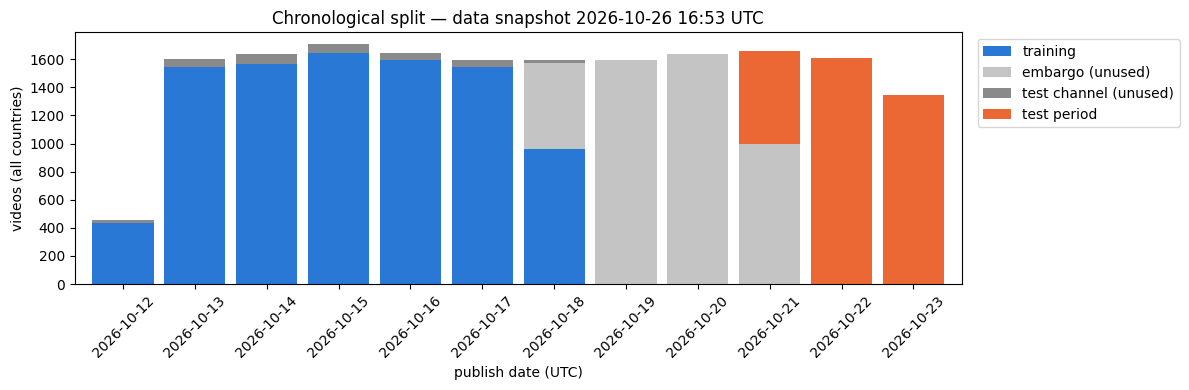

In [ ]:
test_start = model_df["published_at"].iloc[int((1 - TEST_FRACTION) * len(model_df))]
embargo_start = test_start - pd.Timedelta(hours=EMBARGO_HOURS)
in_test_period = model_df["published_at"] >= test_start
test = model_df[in_test_period & model_df["in_study"]]

model_df["role"] = np.select(
    [in_test_period, model_df["published_at"] >= embargo_start, model_df["channel_id"].isin(test["channel_id"])],
    ["test period", "embargo (unused)", "test channel (unused)"],
    default="training",
)
dev = model_df[model_df["role"] == "training"].reset_index(drop=True)

threshold = dev.loc[dev["in_study"], TARGET].quantile(VIRAL_QUANTILE)
print(f"test period starts {test_start:%Y-%m-%d %H:%M} UTC; embargo starts {embargo_start:%Y-%m-%d %H:%M} UTC")
print(f"viral threshold (US+CA training videos): {threshold:,.0f} views at 72h")

role_order = ["training", "embargo (unused)", "test channel (unused)", "test period"]
split_table = pd.DataFrame({
    "all countries": model_df["role"].value_counts(),
    "US+CA": model_df.loc[model_df["in_study"], "role"].value_counts(),
    "US+CA viral": model_df.loc[model_df["in_study"]].groupby("role")[TARGET].apply(lambda v: int((v >= threshold).sum())),
}).reindex(role_order).fillna(0).astype(int)
display(split_table)

daily = model_df.groupby([model_df["published_at"].dt.date, "role"]).size().unstack(fill_value=0).reindex(columns=role_order, fill_value=0)
colors = {"training": "#2a78d6", "embargo (unused)": "#c4c4c4", "test channel (unused)": "#8a8a8a", "test period": "#eb6834"}
ax = daily.plot(kind="bar", stacked=True, figsize=(12, 4), width=0.85, color=[colors[r] for r in daily.columns])
ax.set(xlabel="publish date (UTC)", ylabel="videos (all countries)",
       title=f"Chronological split — data snapshot {data.snapshot_at:%Y-%m-%d %H:%M} UTC")
ax.tick_params(axis="x", rotation=45)
ax.legend(title="", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### Feature check on training data

Coverage, typical value, and rank correlation with 72h views for each feature. This uses **training data only**, so nothing about the test period influences feature choices.

In [ ]:
dev_us = dev[dev["in_study"]]
group_of = {col: group for group, cols in FEATURE_GROUPS.items() for col in cols}
feature_check = pd.DataFrame({
    "group": pd.Series(group_of),
    "non-missing % (training)": dev[ALL_FEATURES].notna().mean().mul(100),
    "median (training)": dev[ALL_FEATURES].median(),
    "Spearman with 72h views (US+CA training)": dev_us[ALL_FEATURES].corrwith(dev_us[TARGET], method="spearman"),
}).loc[ALL_FEATURES]
display(feature_check.round(3))

,group,non-missing % (training),median (training),Spearman with 72h views (US+CA training)
log_views_6h,early performance,100.000,10.026,0.818
log_views_3h,early performance,99.225,8.970,0.743
view_growth_3_to_6h,early performance,99.225,0.782,0.417
like_count_6h,engagement,87.480,467.500,0.744
comment_count_6h,engagement,99.365,4.000,0.398
likes_hidden_6h,engagement,100.000,0.000,0.007
log_subscribers,creator,100.000,12.468,0.242
channel_age_days,creator,100.000,1297.243,-0.137
log_channel_views,creator,100.000,19.131,0.349
log_channel_avg_views,creator,100.000,12.352,0.536


## 3. Cross-validation folds

`StratifiedGroupKFold` on the training set, grouped by channel (a creator's videos never sit in both training and validation) and balanced on the viral rate, repeated `N_REPEATS` times.

All four experiments use **the same folds**, so they can be compared fold by fold:
- each fold's viral threshold is recomputed from that fold's US+CA training videos;
- validation is always the fold's US+CA videos;
- only the training rows change between experiments.

In [ ]:
y_dev = dev[TARGET] >= threshold   # only used to balance the folds

def cv_folds(n_repeats=N_REPEATS):
    # Yields (repeat, fold, training rows [all countries], US+CA validation rows, fold threshold).
    for repeat in range(n_repeats):
        folds = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=repeat)
        for fold, (train_idx, val_idx) in enumerate(folds.split(dev, y_dev, groups=dev["channel_id"])):
            train, val = dev.iloc[train_idx], dev.iloc[val_idx]
            fold_threshold = train.loc[train["in_study"], TARGET].quantile(VIRAL_QUANTILE)
            yield repeat, fold, train, val[val["in_study"]], fold_threshold

fold_table = pd.DataFrame([
    {"repeat": r, "fold": f,
     "train: all countries": len(train), "train: US+CA": int(train["in_study"].sum()),
     "train US+CA viral": int((train.loc[train["in_study"], TARGET] >= t).sum()),
     "validation: US+CA": len(val), "validation viral": int((val[TARGET] >= t).sum()),
     "threshold": round(t)}
    for r, f, train, val, t in cv_folds()
])
display(fold_table[fold_table["repeat"] == 0])
display(fold_table.drop(columns=["repeat", "fold"]).agg(["min", "mean", "max"]).round(0))

,repeat,fold,train: all countries,train: US+CA,train US+CA viral,validation: US+CA,validation viral,threshold
0,0,0,7445,548,55,159,20,708306
1,0,1,7446,558,56,149,11,800609
2,0,2,7486,578,58,129,18,687503
3,0,3,7337,581,59,126,5,840042
4,0,4,7442,563,57,144,16,752969


,train: all countries,train: US+CA,train US+CA viral,validation: US+CA,validation viral,threshold
min,7337.0,532.0,54.0,121.0,5.0,631014.0
mean,7431.0,566.0,57.0,141.0,14.0,756982.0
max,7532.0,586.0,59.0,175.0,25.0,866102.0


## 4. Experiments

| # | Training population | Features |
|---|---|---|
| 1 | US+CA | baseline: log views at 6h |
| 2 | All countries | baseline: log views at 6h |
| 3 | US+CA | all features |
| 4 | All countries | all features |

All four are scored on the same US+CA validation folds:
- experiments 1 vs 2 and 3 vs 4 show whether training on all countries helps;
- experiments 1 vs 3 and 2 vs 4 show what the extra features add beyond 6h views.

In [ ]:
EXPERIMENTS = {
    "1. US+CA, baseline": ("US+CA", BASELINE_FEATURES),
    "2. All countries, baseline": ("All countries", BASELINE_FEATURES),
    "3. US+CA, all features": ("US+CA", ALL_FEATURES),
    "4. All countries, all features": ("All countries", ALL_FEATURES),
}

def training_rows(frame, population):
    return frame[frame["in_study"]] if population == "US+CA" else frame

display(pd.DataFrame([
    {"experiment": name, "training population": population, "features": len(features),
     "training videos": len(training_rows(dev, population)),
     "training viral": int((training_rows(dev, population)[TARGET] >= threshold).sum())}
    for name, (population, features) in EXPERIMENTS.items()
]).set_index("experiment"))

,training population,features,training videos,training viral
experiment,,,,
"1. US+CA, baseline",US+CA,1,707,71
"2. All countries, baseline",All countries,1,9289,854
"3. US+CA, all features",US+CA,16,707,71
"4. All countries, all features",All countries,16,9289,854


### Evaluation harness

`run_experiments(MODELS)` trains every model in every experiment on every fold, and scores it on the fold's US+CA validation videos.

**Metrics:**
- **PR-AUC:** main metric; its random baseline is the viral rate (~0.10).
- **ROC-AUC.**
- **precision@10% / recall@10%:** flag the top 10% of scores and check them against the true labels.

Each model must be an sklearn-style classifier with `predict_proba`. Models that cannot handle NaN need an imputer in a pipeline; XGBoost and recent scikit-learn trees accept NaN directly.

In [ ]:
METRICS = ["PR-AUC", "ROC-AUC", "precision@10%", "recall@10%"]

def score(y_true, scores):
    flagged = scores >= np.quantile(scores, VIRAL_QUANTILE)
    hits = (flagged & y_true).sum()
    return {"PR-AUC": average_precision_score(y_true, scores), "ROC-AUC": roc_auc_score(y_true, scores),
            "precision@10%": hits / flagged.sum(), "recall@10%": hits / y_true.sum()}

def run_experiments(models, experiments=EXPERIMENTS, n_repeats=N_REPEATS):
    rows = []
    for repeat, fold, train, val, fold_threshold in cv_folds(n_repeats):
        y_val = (val[TARGET] >= fold_threshold).to_numpy()
        for experiment, (population, features) in experiments.items():
            train_exp = training_rows(train, population)
            y_train = (train_exp[TARGET] >= fold_threshold).astype(int)
            for model_name, model in models.items():
                fitted = clone(model).fit(train_exp[features], y_train)
                rows.append({"experiment": experiment, "model": model_name, "repeat": repeat, "fold": fold,
                             **score(y_val, fitted.predict_proba(val[features])[:, 1])})
    return pd.DataFrame(rows)

def summarize(results):
    stats = results.groupby(["experiment", "model"], sort=False)[METRICS].agg(["mean", "std"])
    return pd.DataFrame({m: stats[(m, "mean")].map("{:.3f}".format) + " ± " + stats[(m, "std")].map("{:.3f}".format)
                         for m in METRICS})

## 5. Models

| Model | Missing values | Starting settings |
|---|---|---|
| Logistic regression | median imputation + missing-value indicators, then standardised | L2 penalty |
| Decision tree | handled natively by scikit-learn trees | depth-limited, at least 50 videos per leaf |
| Random forest | handled natively | 300 trees, √features per split |
| XGBoost | handled natively | 300 shallow trees, learning rate 0.05, row/column subsampling |

Each model is kept deliberately simple: the training set has only a few hundred US+CA viral videos, so heavily tuned or deep models would overfit.

In [ ]:
BASE_MODELS = {
    "Logistic regression": make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LogisticRegression(max_iter=2000)),
    "Decision tree": DecisionTreeClassifier(max_depth=4, min_samples_leaf=50, random_state=0),
    "Random forest": RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=20,
                                            n_jobs=-1, random_state=0),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=5,
                             subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                             eval_metric="logloss", n_jobs=-1, random_state=0),
}
MODEL_COLORS = dict(zip(BASE_MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))

### Light tuning

One setting per model, chosen by mean PR-AUC on the first CV repeat of experiment 4 (all countries, all features), then reused in every experiment. Because tuning and evaluation share these folds, the CV scores below are slightly optimistic. The locked final test is the honest estimate.

In [ ]:
TUNING_GRID = {
    "Logistic regression": ("logisticregression__C", [0.1, 1.0, 10.0]),
    "Decision tree": ("max_depth", [3, 4, 6]),
    "Random forest": ("min_samples_leaf", [5, 20, 50]),
    "XGBoost": ("max_depth", [2, 3, 5]),
}
TUNE_ON = "4. All countries, all features"

MODELS, tuning_rows = {}, []
for name, (param, values) in TUNING_GRID.items():
    variants = {f"{name}: {v}": clone(BASE_MODELS[name]).set_params(**{param: v}) for v in values}
    tuned = run_experiments(variants, experiments={TUNE_ON: EXPERIMENTS[TUNE_ON]}, n_repeats=1)
    stats = tuned.groupby("model", sort=False)["PR-AUC"].agg(["mean", "std"])
    best = values[int(np.argmax(stats["mean"].to_numpy()))]
    MODELS[name] = clone(BASE_MODELS[name]).set_params(**{param: best})
    tuning_rows += [{"model": name, "setting": param.split("__")[-1], "value": v,
                     "PR-AUC mean": m, "PR-AUC sd": s, "chosen": v == best}
                    for v, (m, s) in zip(values, stats.to_numpy())]
display(pd.DataFrame(tuning_rows).set_index(["model", "setting", "value"]).round(3))

PR-AUC mean  PR-AUC sd  chosen
model               setting          value                                
Logistic regression C                0.1          0.658      0.302    True
                                     1.0          0.651      0.300   False
                                     10.0         0.652      0.301   False
Decision tree       max_depth        3.0          0.552      0.288   False
                                     4.0          0.575      0.292   False
                                     6.0          0.583      0.312    True
Random forest       min_samples_leaf 5.0          0.666      0.317   False
                                     20.0         0.667      0.320    True
                                     50.0         0.661      0.314   False
XGBoost             max_depth        2.0          0.657      0.306   False
                                     3.0          0.662      0.296   False
                                     5.0          0.665      0.311    True

## 6. Results: four experiments × four models

Every model is trained in every experiment on the same folds and scored on the US+CA validation videos. Spreads (±) are standard deviations across folds; with ~14 viral videos per validation fold they are wide.

In [ ]:
cv_results = run_experiments(MODELS)
print(f"{N_REPEATS} × {N_SPLITS}-fold grouped CV; data snapshot {data.snapshot_at:%Y-%m-%d %H:%M} UTC")
display(summarize(cv_results))

print("Mean PR-AUC (rows: model, columns: experiment):")
display(cv_results.pivot_table(index="model", columns="experiment", values="PR-AUC", sort=False).round(3))

3 × 5-fold grouped CV; data snapshot 2026-10-26 16:53 UTC


PR-AUC  \
experiment                     model                                
1. US+CA, baseline             Logistic regression  0.688 ± 0.188   
                               Decision tree        0.515 ± 0.156   
                               Random forest        0.643 ± 0.192   
                               XGBoost              0.640 ± 0.192   
2. All countries, baseline     Logistic regression  0.688 ± 0.188   
                               Decision tree        0.644 ± 0.202   
                               Random forest        0.648 ± 0.213   
                               XGBoost              0.669 ± 0.195   
3. US+CA, all features         Logistic regression  0.681 ± 0.186   
                               Decision tree        0.514 ± 0.154   
                               Random forest        0.647 ± 0.175   
                               XGBoost              0.655 ± 0.190   
4. All countries, all features Logistic regression  0.702 ± 0.191   
                               Decision tree        0.632 ± 0.198   
                               Random forest        0.712 ± 0.197   
                               XGBoost              0.716 ± 0.191   

                                                          ROC-AUC  \
experiment                     model                                
1. US+CA, baseline             Logistic regression  0.932 ± 0.037   
                               Decision tree        0.905 ± 0.065   
                               Random forest        0.919 ± 0.058   
                               XGBoost              0.927 ± 0.036   
2. All countries, baseline     Logistic regression  0.932 ± 0.037   
                               Decision tree        0.889 ± 0.109   
                               Random forest        0.881 ± 0.116   
                               XGBoost              0.913 ± 0.061   
3. US+CA, all features         Logistic regression  0.926 ± 0.040   
                               Decision tree        0.908 ± 0.063   
                               Random forest        0.927 ± 0.042   
                               XGBoost              0.934 ± 0.033   
4. All countries, all features Logistic regression  0.939 ± 0.036   
                               Decision tree        0.905 ± 0.076   
                               Random forest        0.936 ± 0.045   
                               XGBoost              0.931 ± 0.042   

                                                    precision@10%  \
experiment                     model                                
1. US+CA, baseline             Logistic regression  0.577 ± 0.216   
                               Decision tree        0.488 ± 0.216   
                               Random forest        0.567 ± 0.216   
                               XGBoost              0.573 ± 0.198   
2. All countries, baseline     Logistic regression  0.577 ± 0.216   
                               Decision tree        0.561 ± 0.238   
                               Random forest        0.591 ± 0.223   
                               XGBoost              0.572 ± 0.213   
3. US+CA, all features         Logistic regression  0.593 ± 0.202   
                               Decision tree        0.471 ± 0.220   
                               Random forest        0.546 ± 0.200   
                               XGBoost              0.574 ± 0.220   
4. All countries, all features Logistic regression  0.581 ± 0.213   
                               Decision tree        0.549 ± 0.216   
                               Random forest        0.585 ± 0.221   
                               XGBoost              0.609 ± 0.217   

                                                       recall@10%  
experiment                     model                               
1. US+CA, baseline             Logistic regression  0.587 ± 0.187  
                               Decision tree        0.728 ± 0.234  
                               Random forest        0.581 

Mean PR-AUC (rows: model, columns: experiment):


experiment,"1. US+CA, baseline","2. All countries, baseline","3. US+CA, all features","4. All countries, all features"
model,,,,
Logistic regression,0.688,0.688,0.681,0.702
Decision tree,0.515,0.644,0.514,0.632
Random forest,0.643,0.648,0.647,0.712
XGBoost,0.640,0.669,0.655,0.716


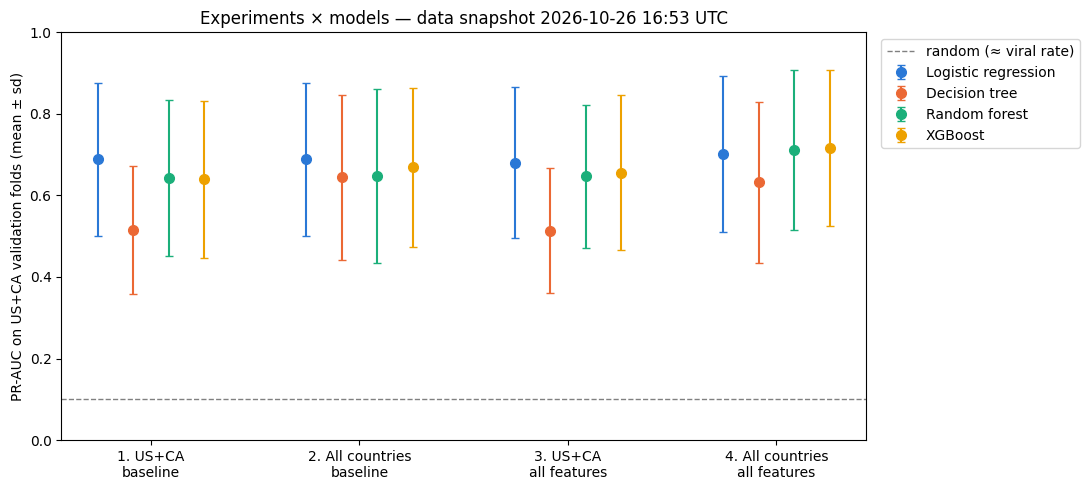

In [ ]:
stats = cv_results.groupby(["experiment", "model"], sort=False)["PR-AUC"].agg(["mean", "std"])
experiments, models = list(EXPERIMENTS), list(MODELS)
fig, ax = plt.subplots(figsize=(11, 5))
for k, model in enumerate(models):
    s = stats.xs(model, level="model").reindex(experiments)
    x = np.arange(len(experiments)) + (k - (len(models) - 1) / 2) * 0.17
    ax.errorbar(x, s["mean"], yerr=s["std"], fmt="o", ms=7, capsize=3, color=MODEL_COLORS[model], label=model)
ax.axhline(1 - VIRAL_QUANTILE, color="gray", ls="--", lw=1, label="random (≈ viral rate)")
ax.set_xticks(range(len(experiments)), [e.replace(", ", "\n") for e in experiments])
ax.set(ylabel="PR-AUC on US+CA validation folds (mean ± sd)", ylim=(0, 1),
       title=f"Experiments × models — data snapshot {data.snapshot_at:%Y-%m-%d %H:%M} UTC")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### Answering the two experiment questions, fold by fold

Folds differ a lot in difficulty, so each comparison is made **within the same fold** and then averaged. "Folds better" is the share of the 15 folds where the first setup beat the second.
- **Training population:** experiment 4 vs 3 (all features) and 2 vs 1 (baseline).
- **Feature set:** experiment 3 vs 1 (US+CA training) and 4 vs 2 (all-countries training).

In [ ]:
pr = cv_results.pivot_table(index=["repeat", "fold", "model"], columns="experiment", values="PR-AUC")
COMPARISONS = {
    "All countries vs US+CA training — all features": ("4. All countries, all features", "3. US+CA, all features"),
    "All countries vs US+CA training — baseline": ("2. All countries, baseline", "1. US+CA, baseline"),
    "All features vs baseline — US+CA training": ("3. US+CA, all features", "1. US+CA, baseline"),
    "All features vs baseline — all-countries training": ("4. All countries, all features", "2. All countries, baseline"),
}
rows = []
for label, (a, b) in COMPARISONS.items():
    for model, diff in (pr[a] - pr[b]).groupby(level="model", sort=False):
        rows.append({"comparison": label, "model": model,
                     "mean PR-AUC gain": round(diff.mean(), 3), "sd": round(diff.std(), 3),
                     "folds better": f"{(diff > 0).mean():.0%}"})
display(pd.DataFrame(rows).set_index(["comparison", "model"]))

mean PR-AUC gain  \
comparison                                        model                                   
All countries vs US+CA training — all features    Decision tree                   0.118   
                                                  Logistic regression             0.022   
                                                  Random forest                   0.065   
                                                  XGBoost                         0.061   
All countries vs US+CA training — baseline        Decision tree                   0.129   
                                                  Logistic regression             0.000   
                                                  Random forest                   0.005   
                                                  XGBoost                         0.029   
All features vs baseline — US+CA training         Decision tree                  -0.002   
                                                  Logistic regression            -0.008   
                                                  Random forest                   0.004   
                                                  XGBoost                         0.015   
All features vs baseline — all-countries training Decision tree                  -0.012   
                                                  Logistic regression             0.014   
                                                  Random forest                   0.064   
                                                  XGBoost                         0.047   

                                                                          sd  \
comparison                                        model                        
All countries vs US+CA training — all features    Decision tree        0.117   
                                                  Logistic regression  0.046   
                                                  Random forest        0.063   
                                                  XGBoost              0.097   
All countries vs US+CA training — baseline        Decision tree        0.091   
                                                  Logistic regression  0.000   
                                                  Random forest        0.072   
                                                  XGBoost              0.052   
All features vs baseline — US+CA training         Decision tree        0.016   
                                                  Logistic regression  0.020   
                                                  Random forest        0.097   
                                                  XGBoost              0.067   
All features vs baseline — all-countries training Decision tree        0.048   
                                                  Logistic regression  0.039   
                                                  Random forest        0.063   
                                                  XGBoost              0.068   

                                                                      folds better  
comparison                                        model                             
All countries vs US+CA training — all features    Decision tree                80%  
                                                  Logistic regression          67%  
                                                  Random forest                80%  
                                                  XGBoost                      73%  
All countries vs US+CA training — baseline        Decision tree                87%  
                                                  Logistic regression           0%  
                                                  Random forest                53%  
                                                  XGBoost                      73%  
All features vs baseline — US+CA training         Decision tree                27%  
                                                  Logist

### What does the best all-features model use?

Permutation importance for the best model in experiment 4, measured on the US+CA validation folds of the first CV repeat. It shows the drop in PR-AUC when one feature is shuffled. Correlated features (for example views and likes at 6h) share credit, so the group totals are easier to read than single features. These are associations, not causal effects.

In [ ]:
exp4_means = cv_results[cv_results["experiment"] == TUNE_ON].groupby("model")["PR-AUC"].mean()
importance_model = exp4_means.idxmax()
group_of = {col: group for group, cols in FEATURE_GROUPS.items() for col in cols}

drops = []
for repeat, fold, train, val, fold_threshold in cv_folds(n_repeats=1):
    fitted = clone(MODELS[importance_model]).fit(train[ALL_FEATURES], (train[TARGET] >= fold_threshold).astype(int))
    result = permutation_importance(fitted, val[ALL_FEATURES], (val[TARGET] >= fold_threshold).astype(int),
                                    scoring="average_precision", n_repeats=5, random_state=0)
    drops.append(result.importances_mean)

importance = (pd.DataFrame({"feature": ALL_FEATURES, "PR-AUC drop": np.mean(drops, axis=0)})
              .assign(group=lambda d: d["feature"].map(group_of))
              .sort_values("PR-AUC drop", ascending=False).set_index("feature"))
print(f"Model: {importance_model} (experiment 4)")
display(importance.round(4))
display(importance.groupby("group")["PR-AUC drop"].sum().sort_values(ascending=False).round(4).to_frame())

Model: XGBoost (experiment 4)


,PR-AUC drop,group
feature,,
log_views_6h,0.2887,early performance
like_count_6h,0.1057,engagement
log_channel_avg_views,0.0694,creator
view_growth_3_to_6h,0.0328,early performance
comment_count_6h,0.0272,engagement
log_views_3h,0.0173,early performance
log_subscribers,0.0068,creator
emoji_count,0.0039,content
channel_age_days,0.0036,creator


,PR-AUC drop
group,
early performance,0.3388
engagement,0.1328
creator,0.0751
content,0.0015
timing,-0.0080


## 7. Final test (run once, at the end)

The chosen setup is the experiment and model with the highest mean cross-validated PR-AUC. You can override it below, for example to prefer a simpler model when the difference is within noise, but do so **before** running the test.

On the frozen data copy, set `RUN_FINAL_TEST = True` and run the notebook once. The chosen model is refit on the full training set and scored on the held-out US+CA test videos, next to the plain 6h-views rule. Do not change the model after looking at the test result.

In [ ]:
CHOSEN_EXPERIMENT, CHOSEN_MODEL = cv_results.groupby(["experiment", "model"])["PR-AUC"].mean().idxmax()
print(f"Chosen by cross-validation: {CHOSEN_MODEL} in '{CHOSEN_EXPERIMENT}'")

def final_test(model_name, experiment):
    population, features = EXPERIMENTS[experiment]
    train = training_rows(dev, population)
    fitted = clone(MODELS[model_name]).fit(train[features], (train[TARGET] >= threshold).astype(int))
    y_test = (test[TARGET] >= threshold).to_numpy()
    print(f"Final test — data snapshot {data.snapshot_at:%Y-%m-%d %H:%M} UTC; {len(test):,} US+CA videos, {y_test.sum()} viral")
    return pd.DataFrame({
        "rule: views at 6h": score(y_test, test["views_6h"].to_numpy()),
        f"{model_name} ({experiment})": score(y_test, fitted.predict_proba(test[features])[:, 1]),
    }).T.round(3)

if RUN_FINAL_TEST:
    display(final_test(CHOSEN_MODEL, CHOSEN_EXPERIMENT))
else:
    print("Final test is locked. Set RUN_FINAL_TEST = True on the frozen data copy and run once.")

Chosen by cross-validation: XGBoost in '4. All countries, all features'
Final test is locked. Set RUN_FINAL_TEST = True on the frozen data copy and run once.
